In [22]:
! pip install altair

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 660.9 kB/s  0:00:01 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [altair]━━━━ 1/2 [altair]


In [527]:
import matplotlib.pyplot as plt

plt.style.use('classic')

# 2. Enforce the classic monospace look globally
plt.rcParams['font.family'] = 'monospace'

In [644]:
df = pd.read_csv('../backtests/neutral_width_check_3_2026-03-19_20261005T151900777667Z/fills.csv')
df.annualized_volatility *= 100

In [652]:
df = pd.read_csv('../backtests/neutral_width_check_3_2026-03-19_20261005T160607863303Z/fills.csv')
df.annualized_volatility *= 100

In [653]:
df = df[df.full_width_ticks > 50]

In [655]:
df = df[df.full_width_ticks > 75]

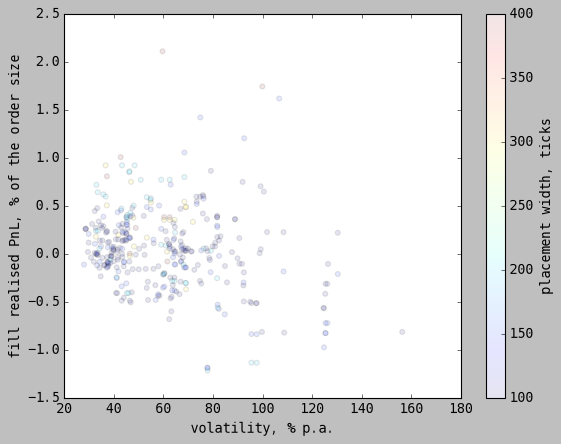

In [656]:
plt.scatter(df.annualized_volatility, df.realized_pnl_from_fill / (df.quantity * df.fill_price) * 100, c=df.full_width_ticks, alpha=0.1)
plt.xlabel('volatility, % p.a.')
plt.ylabel('fill realised PnL, % of the order size')
plt.colorbar(label='placement width, ticks')

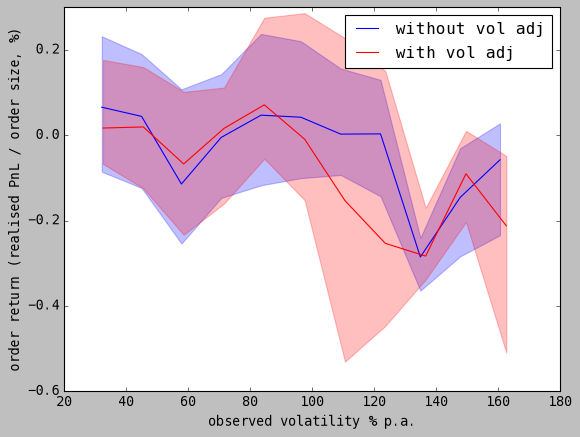

In [667]:
for fname, label, c in [
    (
        '../backtests/neutral_width_check_3_2026-03-19_20261005T151900777667Z/fills.csv',
        'without vol adj',
        'b'
    ),
    (
        '../backtests/neutral_width_check_3_2026-03-19_20261005T160607863303Z/fills.csv',
        'with vol adj',
        'r'
    )
]:
    df = pd.read_csv(fname)
    # df = df[df.full_width_ticks > 75]
    df.annualized_volatility *= 100
    vol_min, vol_max = df.annualized_volatility.min(), df.annualized_volatility.max()
    n_bins = 10
    
    step = (vol_max - vol_min) / n_bins
    
    df['vol_bin'] = (df.annualized_volatility // step * step) + step/2
    df['order_return'] = df.realized_pnl_from_fill / (df.quantity * df.fill_price) * 100
    
    q25 = df.groupby('vol_bin').order_return.quantile(0.25)
    q50 = df.groupby('vol_bin').order_return.quantile(0.50)
    q75 = df.groupby('vol_bin').order_return.quantile(0.75)
    
    x = q50.index
    
    plt.fill_between(
        x,
        q25.values,
        q75.values,
        alpha=0.25,
        # label='q25–q75', 
        color=c
    )
    
    plt.plot(x, q50.values, label=label, c=c)
    
    plt.legend()
    plt.xlabel('observed volatility % p.a.')
    plt.ylabel('order return (realised PnL / order size, %)')

Text(0, 0.5, 'order return (realised PnL / order size, %)')

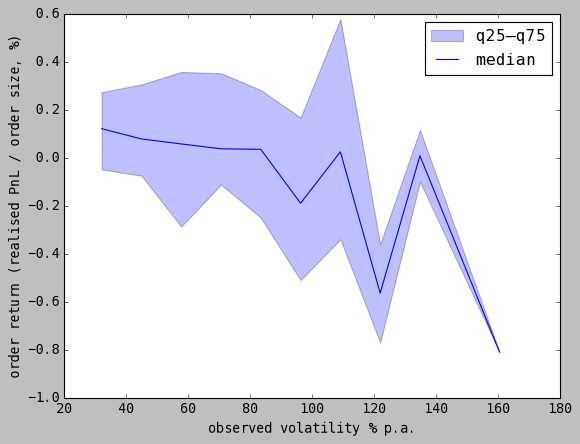

In [657]:
vol_min, vol_max = df.annualized_volatility.min(), df.annualized_volatility.max()
n_bins = 10

step = (vol_max - vol_min) / n_bins

df['vol_bin'] = (df.annualized_volatility // step * step) + step/2
df['order_return'] = df.realized_pnl_from_fill / (df.quantity * df.fill_price) * 100

q25 = df.groupby('vol_bin').order_return.quantile(0.25)
q50 = df.groupby('vol_bin').order_return.quantile(0.50)
q75 = df.groupby('vol_bin').order_return.quantile(0.75)

x = q50.index

plt.fill_between(
    x,
    q25.values,
    q75.values,
    alpha=0.25,
    label='q25–q75'
)

plt.plot(x, q50.values, label='median')

plt.legend()
plt.xlabel('observed volatility % p.a.')
plt.ylabel('order return (realised PnL / order size, %)')

Text(0, 0.5, 'order return (realised PnL / order size, %)')

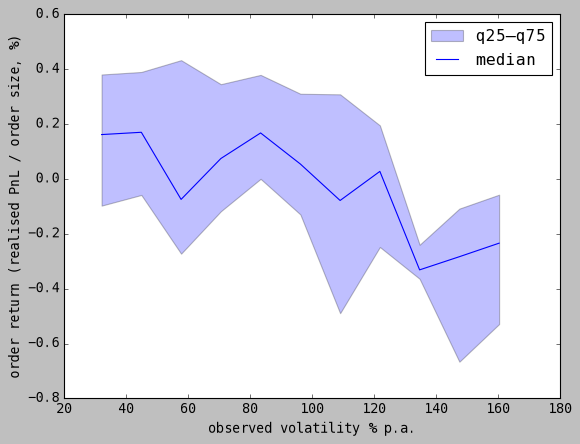

In [650]:
vol_min, vol_max = df.annualized_volatility.min(), df.annualized_volatility.max()
n_bins = 10

step = (vol_max - vol_min) / n_bins

df['vol_bin'] = (df.annualized_volatility // step * step) + step/2
df['order_return'] = df.realized_pnl_from_fill / (df.quantity * df.fill_price) * 100

q25 = df.groupby('vol_bin').order_return.quantile(0.25)
q50 = df.groupby('vol_bin').order_return.quantile(0.50)
q75 = df.groupby('vol_bin').order_return.quantile(0.75)

x = q50.index

plt.fill_between(
    x,
    q25.values,
    q75.values,
    alpha=0.25,
    label='q25–q75'
)

plt.plot(x, q50.values, label='median')

plt.legend()
plt.xlabel('observed volatility % p.a.')
plt.ylabel('order return (realised PnL / order size, %)')

Text(0, 0.5, 'order return (realiased PnL / order size, %')

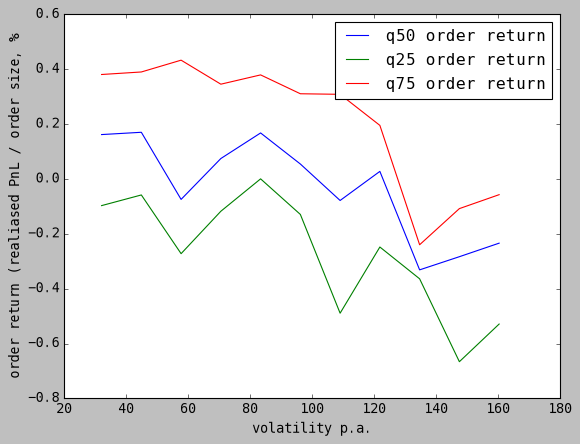

In [630]:
df.groupby('vol_bin').order_return.quantile(0.5).plot(label='q50 order return')
df.groupby('vol_bin').order_return.quantile(0.25).plot(label='q25 order return')
df.groupby('vol_bin').order_return.quantile(0.75).plot(label='q75 order return')
plt.legend()
plt.xlabel('volatility p.a.')
plt.ylabel('order return (realiased PnL / order size, %')

In [573]:
((df.annualized_volatility // step * step) + step/2).unique()

array([0.38471686, 0.64119477, 0.89767267, 1.15415058, 1.41062848,
       1.66710639])

In [566]:
step

np.float64(0.2564779060647971)

In [565]:
vol_min

np.float64(0.2819302217494449)

In [564]:
vol_max

np.float64(1.5643197520734302)

In [567]:
np.linspace(df.annualized_volatility.min(), df.annualized_volatility.max(), n_bins) + step / 2

array([0.41016917, 0.73076656, 1.05136394, 1.37196132, 1.69255871])

In [558]:
np.linspace(df.annualized_volatility.min(), df.annualized_volatility.max(), 20-1)

array([0.28193022, 0.35317408, 0.42441795, 0.49566181, 0.56690567,
       0.63814954, 0.7093934 , 0.78063726, 0.85188112, 0.92312499,
       0.99436885, 1.06561271, 1.13685658, 1.20810044, 1.2793443 ,
       1.35058816, 1.42183203, 1.49307589, 1.56431975])

In [551]:
df

,fill_number,timestamp_ns,book_timestamp_ns,order_id,side,best_bid,best_ask,pre_fill_mid,trade_price,fill_price,...,activation_timestamp_ns,trade_timestamp_ns,queue_ahead_before,queue_ahead_after,fill_reason,full_width_ticks,full_quote_width_ticks_at_placement,half_spread_ticks_before_fill,position_size_before_fill,position_size_after_fill
2817,1,1773882323068508695,1773882323046054562,269,buy,2190.1,2190.2,2190.15,2189.5,2189.95,...,1773882322886503476,1773882323068508695,0.000,0.0,strict_trade_through,100.0,100.0,50.0,0.000,0.045
2818,2,1773884053050287102,1773884052943387873,1438,sell,2193.1,2193.2,2193.15,2193.6,2193.55,...,1773884052584594261,1773884053050287102,0.000,0.0,strict_trade_through,100.0,100.0,50.0,0.045,-0.003
2819,3,1773884259291925809,1773884259261718610,1602,sell,2197.5,2197.9,2197.70,2198.0,2197.95,...,1773884255992410706,1773884259291925809,0.000,0.0,strict_trade_through,100.0,100.0,50.0,-0.003,-0.047
2820,4,1773884774697574100,1773884774690647268,1940,sell,2199.9,2200.0,2199.95,2200.4,2200.35,...,1773884735621874694,1773884774697574100,0.000,0.0,strict_trade_through,100.0,100.0,50.0,-0.047,-0.089
2821,5,1773884774755933319,1773884774741538703,1942,sell,2200.9,2201.4,2201.15,2201.2,2200.45,...,1773884774740647268,1773884774755933319,0.000,0.0,strict_trade_through,100.0,100.0,50.0,-0.089,-0.131
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4403,45,1773949372516542495,1773949372509086667,75985,buy,2145.4,2146.8,2146.10,2144.8,2145.10,...,1773949372202426127,1773949372516542495,196.196,0.0,strict_trade_through,400.0,400.0,200.0,0.122,0.161
4404,46,1773959592755678319,1773959592720702828,81905,buy,2143.2,2143.7,2143.45,2141.7,2141.99,...,1773959592738510332,1773959592755678319,0.000,0.0,strict_trade_through,400.0,400.0,200.0,0.161,0.199
4405,47,1773959750728574573,1773959750696079116,82067,buy,2137.5,2137.6,2137.55,2137.5,2138.14,...,1773959750363333893,1773959750728574573,0.000,0.0,strict_trade_through,400.0,400.0,200.0,0.199,0.235
4406,48,1773959783724941806,1773959783723618519,82117,buy,2133.2,2133.3,2133.25,2133.2,2133.28,...,1773959783308714290,1773959783724941806,0.000,0.0,strict_trade_through,400.0,400.0,200.0,0.235,0.269


In [603]:
df['sign'] = df.side.apply(lambda x: {'buy': -1, 'sell': 1}[x])
plt.scatter(df.sign * df.trend_magnitude, df.realized_pnl_from_fill, c=df.annualized_volatility, alpha=0.1)
plt.colorbar()

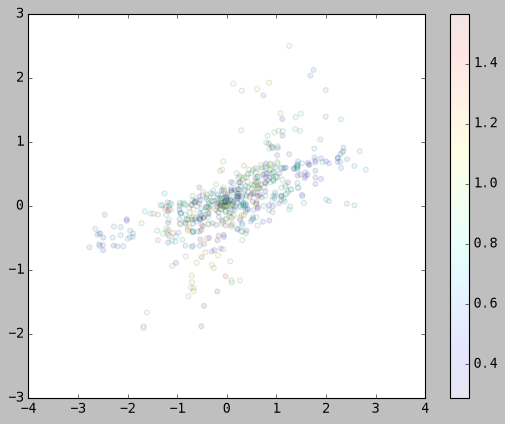

In [604]:
plt.scatter(df.sign * df.trend_magnitude, df.realized_pnl_from_fill, c=df.annualized_volatility, alpha=0.1)
plt.colorbar()

In [123]:
df.recorded_execution_pnl.sum()

np.float64(-4.312490000000308)

In [160]:
df['pnl_bps'] = df.rea

In [155]:
df.columns

Index(['fill_number', 'timestamp_ns', 'book_timestamp_ns', 'order_id', 'side',
       'best_bid', 'best_ask', 'pre_fill_mid', 'trade_price', 'fill_price',
       'quantity', 'expected_execution_pnl', 'recorded_execution_pnl',
       'audit_error', 'fee', 'funding_rate', 'orderbook_imbalance_5',
       'annualized_volatility', 'trend_magnitude', 'position_effect',
       'average_entry_price_before_fill', 'realized_pnl_from_fill'],
      dtype='str')

In [202]:
6*3*3

54

In [266]:
df = pd.read_csv('../backtests/neutral_trend_grid_2026-03-19_24h_20261004T170523705396Z/summary.csv')

In [430]:
df = pd.read_csv('../backtests/neutral_staged_grid_2026-03-19_24h_20261005T032256882640Z/summary.csv')

In [431]:
df = df.set_index('run_id')

In [432]:
df.columns

Index(['first_stage', 'first_stage_turnover_eligible', 'run_directory',
       'order_fraction', 'requote_interval_ms', 'target_annual_volatility',
       'warmup_seconds', 'half_spread_ticks_at_target', 'half_life_seconds',
       'trend_skew_strength', 'window_start_utc', 'window_end_utc',
       'window_start_ns', 'window_end_ns', 'requested_hours',
       'effective_hours', 'window_trimmed', 'initial_cash_usd',
       'maker_fee_rate', 'latency_ms', 'market_events', 'n_fills',
       'traded_notional_usd', 'turnover', 'total_pnl_usd', 'final_equity_usd',
       'max_drawdown_usd', 'max_drawdown_fraction',
       'min_unrealized_pnl_equity_fraction', 'annualized_mu',
       'annualized_sigma', 'sharpe', 'return_samples',
       'return_interval_minutes', 'trading_fees_usd', 'funding_pnl_usd',
       'execution_pnl_usd', 'inventory_pnl_usd', 'final_position_size',
       'max_fill_attribution_error', 'wall_seconds', 'turnover_24h'],
      dtype='str')

In [425]:
df = df[df.first_stage == 2]

<Axes: xlabel='trend_skew_strength'>

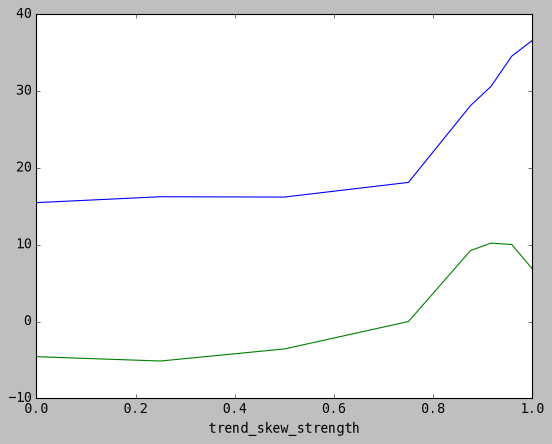

In [437]:
df.groupby('trend_skew_strength').total_pnl_usd.max().plot()
df.groupby('trend_skew_strength').total_pnl_usd.mean().plot()

In [444]:
df[df.first_stage == 2].half_life_seconds.unique()

array([ 7916.37028088,  8779.94883324,  9737.73317559, 10800.        ])

In [450]:
df[df.f

run_id
126    3.706325
127    3.702293
128    3.673871
129    3.721152
130    3.863626
         ...   
232    1.153897
233    1.063718
234    1.158406
235    1.091156
236    1.109598
Name: turnover, Length: 111, dtype: float64

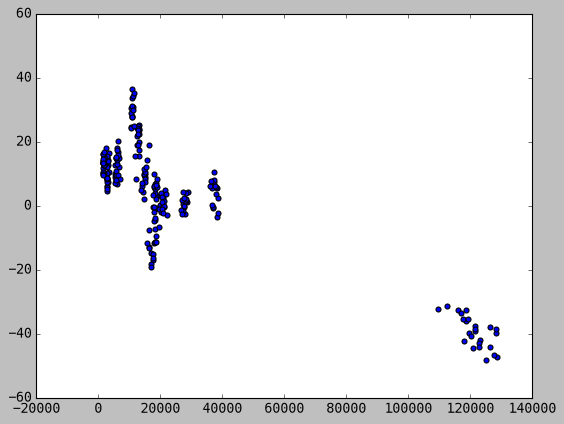

In [452]:
plt.scatter(df[df.first_stage <= 2].traded_notional_usd, df[df.first_stage <= 2].total_pnl_usd)

In [447]:
df[df.first_stage == 2].iloc[df[df.first_stage == 2].sharpe.argmax()]

first_stage                                                   2
first_stage_turnover_eligible                               NaN
run_directory                                           run_224
order_fraction                                             0.01
requote_interval_ms                                       500.0
target_annual_volatility                                    0.5
warmup_seconds                                           3600.0
half_spread_ticks_at_target                             109.375
half_life_seconds                                   7916.370281
trend_skew_strength                                         1.0
window_start_utc                      2026-03-19T00:00:00+00:00
window_end_utc                        2026-03-20T00:00:00+00:00
window_start_ns                             1773878400000000000
window_end_ns                               1773964800000000000
requested_hours                                            24.0
effective_hours                         

In [441]:
df.iloc[df.total_pnl_usd.argmax()]

first_stage                                                   2
first_stage_turnover_eligible                               NaN
run_directory                                           run_228
order_fraction                                             0.01
requote_interval_ms                                       500.0
target_annual_volatility                                    0.5
warmup_seconds                                           3600.0
half_spread_ticks_at_target                             109.375
half_life_seconds                                   8779.948833
trend_skew_strength                                         1.0
window_start_utc                      2026-03-19T00:00:00+00:00
window_end_utc                        2026-03-20T00:00:00+00:00
window_start_ns                             1773878400000000000
window_end_ns                               1773964800000000000
requested_hours                                            24.0
effective_hours                         

In [272]:
6570 / 60 

109.5

In [245]:
np.linspace(0.0, 1.0, 5)

array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [249]:
0.25 + np.linspace(-0.5, 0.5, 5) / 4

array([0.125 , 0.1875, 0.25  , 0.3125, 0.375 ])

In [250]:
tuple(900.0 * 12.0 ** (i / 5) for i in range(6))

(900.0,
 1479.3766465655033,
 2431.7280693371044,
 3997.157462861256,
 6570.334892446623,
 10800.0)

In [260]:
6570.3 / 60

109.50500000000001

In [251]:
10800.0 / 3600


3.0

In [265]:
np.geomspace(1.5 * 3600, 2.2 * 3600, 6)

array([5400.        , 5829.88575445, 6293.9940574 , 6795.04931367,
       7335.99281381, 7920.        ])

In [289]:
x_cols = [
    "half_spread_ticks_at_target",
    "half_life_seconds",
    "trend_skew_strength"
]

grid = (
    df
    .set_index(x_cols)["total_pnl_usd"]
    .sort_index()
)

In [291]:
def add_discrete_curvature(df, x_cols, y_col="y"):
    df = df.copy()

    # Sorted unique coordinate values along every axis
    axes = {
        x: np.sort(df[x].unique())
        for x in x_cols
    }

    lookup = {
        tuple(row[x] for x in x_cols): row[y_col]
        for _, row in df.iterrows()
    }

    laplacians = []
    roughness = []
    n_neighbors = []

    for _, row in df.iterrows():
        point = tuple(row[x] for x in x_cols)
        y0 = row[y_col]

        lap = 0.0
        rough = 0.0
        count = 0

        for j, x in enumerate(x_cols):
            vals = axes[x]
            value = row[x]

            k = np.searchsorted(vals, value)

            # Need both left and right neighbor
            if k == 0 or k == len(vals) - 1:
                continue

            left = list(point)
            right = list(point)

            left[j] = vals[k - 1]
            right[j] = vals[k + 1]

            left = tuple(left)
            right = tuple(right)

            if left not in lookup or right not in lookup:
                continue

            y_left = lookup[left]
            y_right = lookup[right]

            d2 = y_right - 2 * y0 + y_left

            lap += d2
            rough += d2**2
            count += 1

        laplacians.append(lap if count else np.nan)
        roughness.append(rough if count else np.nan)
        n_neighbors.append(count)

    df["laplacian"] = laplacians
    df["curvature_energy"] = roughness
    df["n_valid_axes"] = n_neighbors

    return df

In [294]:
df = add_discrete_curvature(df, x_cols, y_col="total_pnl_usd")

In [301]:
df

,run_id,run_directory,order_fraction,requote_interval_ms,half_spread_ticks_at_target,half_life_seconds,trend_skew_strength,window_start_utc,window_end_utc,initial_cash_usd,...,trading_fees_usd,funding_pnl_usd,execution_pnl_usd,inventory_pnl_usd,final_position_size,max_fill_attribution_error,wall_seconds,laplacian,curvature_energy,n_valid_axes
0,1,run_001,0.01,500.0,100.0,5400.0,0.1250,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,4.012987,-0.041093,1.81520,8.63830,0.556,1.110223e-16,109.806725,NaN,NaN,0
1,2,run_002,0.01,500.0,100.0,5400.0,0.1875,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,4.066623,0.000676,1.69798,10.79885,0.605,1.110223e-16,108.987563,-4.052017,16.418845,1
2,3,run_003,0.01,500.0,100.0,5400.0,0.2500,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,4.143706,0.084375,1.67941,8.79025,0.587,1.075529e-16,108.973548,3.108563,9.663162,1
3,4,run_004,0.01,500.0,100.0,5400.0,0.3125,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,4.131849,0.094836,1.78415,9.75120,0.574,1.110223e-16,111.098276,2.246148,5.045180,1
4,5,run_005,0.01,500.0,100.0,5400.0,0.3750,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,4.129255,0.125048,1.75850,13.07820,0.608,1.110223e-16,109.160002,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,86,run_086,0.01,500.0,200.0,7920.0,0.1250,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,0.731447,0.029617,0.80957,21.15420,0.206,5.551115e-17,103.066999,NaN,NaN,0
86,87,run_087,0.01,500.0,200.0,7920.0,0.1875,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,0.751976,0.043090,0.75760,17.96060,0.218,5.030698e-17,102.922091,6.494359,42.176700,1
87,88,run_088,0.01,500.0,200.0,7920.0,0.2500,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,0.731449,0.029617,0.79868,21.15420,0.206,5.551115e-17,102.944954,-2.785819,7.760789,1
88,89,run_089,0.01,500.0,200.0,7920.0,0.3125,2026-03-19T00:00:00+00:00,2026-03-20T00:00:00+00:00,10000.0,...,0.784777,0.043310,0.82098,21.62745,0.258,5.551115e-17,103.390610,-3.089210,9.543221,1


In [303]:
d = df.sort_values('total_pnl_usd').loc[:, [
    *x_cols, "total_pnl_usd", "laplacian", "curvature_energy", "n_valid_axes"
]]

In [344]:
d

,half_spread_ticks_at_target,half_life_seconds,trend_skew_strength,total_pnl_usd,laplacian,curvature_energy,n_valid_axes
0,100.0,5400.000000,0.1250,6.399420,NaN,NaN,0
2,100.0,5400.000000,0.2500,6.410329,3.108563,9.663162,1
24,100.0,7335.992814,0.3750,6.512786,11.703934,136.982077,1
21,100.0,7335.992814,0.1875,6.598660,6.658580,22.198885,2
6,100.0,5829.885754,0.1875,6.798321,7.531587,28.437803,2
...,...,...,...,...,...,...,...
50,150.0,7335.992814,0.1250,29.872400,-32.834636,985.208352,2
45,150.0,6795.049314,0.1250,29.872750,-33.112592,899.740868,2
46,150.0,6795.049314,0.1875,29.930643,-34.437300,1078.426826,3
53,150.0,7335.992814,0.3125,30.029446,-33.442814,805.282744,3


In [ ]:
d.multiply

In [312]:
d.loc[:, ['total_pnl_usd']]

,total_pnl_usd
0,6.399420
2,6.410329
24,6.512786
21,6.598660
6,6.798321
...,...
50,29.872400
45,29.872750
46,29.930643
53,30.029446


In [353]:
def get_mass_centre(count: int, label = 'total_pnl_usd'):
    Xy = d.sort_values(label).iloc[-count:].loc[:, [*x_cols, label]].values
    X, y = Xy[:,:-1], Xy[:, -1]
    return np.multiply(X, y[:, np.newaxis]).sum(axis=0) / y.sum()

In [356]:
{*[1, 2, 3]}

{1, 2, 3}

In [ ]:
{k: v for ..}

In [361]:
len(d)

90

In [362]:
stat = [{
    "count": count,
    **{f"x_{i}": get_mass_centre(count)[i] for i in range(len(x_cols))}
} for count in range(2, len(d)) ]

In [363]:
st = pd.DataFrame(stat).set_index('count')

In [375]:
x_cols

['half_spread_ticks_at_target', 'half_life_seconds', 'trend_skew_strength']

In [374]:
get_mass_centre(20)

array([1.50000000e+02, 6.99641113e+03, 2.30825641e-01])

In [378]:
np.geomspace(1.5 * 3600, 2.2 * 3600, 6)

array([5400.        , 5829.88575445, 6293.9940574 , 6795.04931367,
       7335.99281381, 7920.        ])

In [373]:
get_mass_centre(40)

array([1.60492221e+02, 6.69306543e+03, 2.40792270e-01])

In [382]:
cells = {field: d[field].unique() for field in x_cols}

In [384]:
cells

{'half_spread_ticks_at_target': array([100., 200., 150.]),
 'half_life_seconds': array([5400.        , 7335.99281381, 5829.88575445, 7920.        ,
        6293.9940574 , 6795.04931367]),
 'trend_skew_strength': array([0.125 , 0.25  , 0.375 , 0.1875, 0.3125])}

In [394]:
cells['half_spread_ticks_at_target'][np.argmin(np.abs(cells['half_spread_ticks_at_target'] - 70))]

np.float64(100.0)

In [397]:
def get_cell(x):
    return {
        field: cells[field][np.argmin(np.abs(cells[field] - x[i]))]
        for i, field in enumerate(cells)
    }
        

In [403]:
stat = pd.DataFrame([
    {**get_cell(get_mass_centre(count)), "count": count}
    for count in range(2, 90)
])

In [412]:
stat.set_index('count').loc[40]

half_spread_ticks_at_target     150.000000
half_life_seconds              6795.049314
trend_skew_strength               0.250000
Name: 40, dtype: float64

In [414]:
d.sort_values('total_pnl_usd')

,half_spread_ticks_at_target,half_life_seconds,trend_skew_strength,total_pnl_usd,laplacian,curvature_energy,n_valid_axes
0,100.0,5400.000000,0.1250,6.399420,NaN,NaN,0
2,100.0,5400.000000,0.2500,6.410329,3.108563,9.663162,1
24,100.0,7335.992814,0.3750,6.512786,11.703934,136.982077,1
21,100.0,7335.992814,0.1875,6.598660,6.658580,22.198885,2
6,100.0,5829.885754,0.1875,6.798321,7.531587,28.437803,2
...,...,...,...,...,...,...,...
50,150.0,7335.992814,0.1250,29.872400,-32.834636,985.208352,2
45,150.0,6795.049314,0.1250,29.872750,-33.112592,899.740868,2
46,150.0,6795.049314,0.1875,29.930643,-34.437300,1078.426826,3
53,150.0,7335.992814,0.3125,30.029446,-33.442814,805.282744,3


<Axes: xlabel='count'>

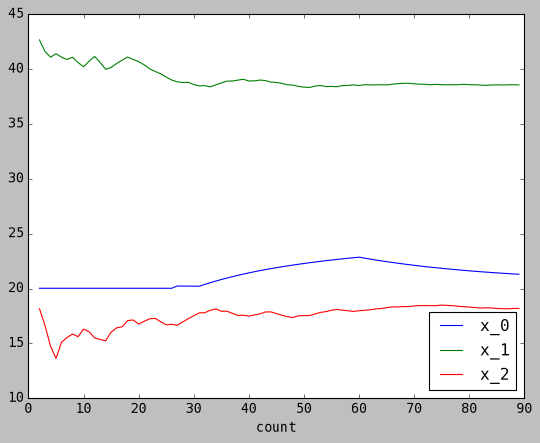

In [379]:
(st / st.std(axis=0)).plot()

In [355]:
get_mass_centre(30)

array([1.51429854e+02, 6.63765605e+03, 2.41313536e-01])

In [327]:
Xy = d.loc[:, [*x_cols, 'total_pnl_usd']].values

In [332]:
X, y = Xy[:,:-1], Xy[:, -1]

In [334]:
X * y

ValueError: operands could not be broadcast together with shapes (90,3) (90,) 

In [340]:
y = y - y.min()

In [343]:
np.multiply(X, np.exp(y)[:, np.newaxis]).sum(axis=0) / np.exp(y).sum()

array([1.50023128e+02, 7.04005163e+03, 2.15680618e-01])

In [339]:
np.multiply(X, y[:, np.newaxis]).sum(axis=0) / y.sum()

array([1.59331707e+02, 6.62602310e+03, 2.49938798e-01])

In [314]:
d.loc[:, x_cols] * d.loc[:, ['total_pnl_usd']]

,half_spread_ticks_at_target,half_life_seconds,trend_skew_strength
0,200.0,10800.000000,0.250
2,200.0,10800.000000,0.500
24,200.0,14671.985628,0.750
21,200.0,14671.985628,0.375
6,200.0,11659.771509,0.375
...,...,...,...
50,300.0,14671.985628,0.250
45,300.0,13590.098627,0.250
46,300.0,13590.098627,0.375
53,300.0,14671.985628,0.625


<Axes: xlabel='total_pnl_usd'>

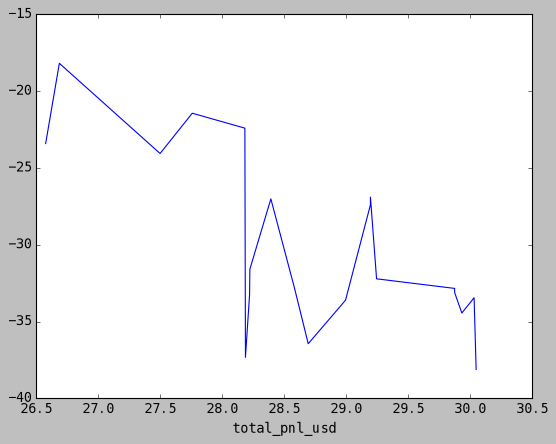

In [299]:
df.sort_values('total_pnl_usd').loc[:, [
    *x_cols, "total_pnl_usd", "laplacian", "curvature_energy", "n_valid_axes"
]].iloc[-20:].set_index('total_pnl_usd').laplacian.plot()

In [290]:
grid

half_spread_ticks_at_target  half_life_seconds  trend_skew_strength
100.0                        5400.0             0.1250                  6.399420
                                                0.1875                  8.430883
                                                0.2500                  6.410329
                                                0.3125                  7.498337
                                                0.3750                 10.832493
                                                                         ...    
200.0                        7920.0             0.1250                 21.261940
                                                0.1875                 18.009314
                                                0.2500                 21.251048
                                                0.3125                 21.706963
                                                0.3750                 19.073667
Name: total_pnl_usd, Length: 90, dtype: f

In [ ]:
df = df.loc[""]

In [288]:
df.total_pnl_usd

0      6.399420
1      8.430883
2      6.410329
3      7.498337
4     10.832493
        ...    
85    21.261940
86    18.009314
87    21.251048
88    21.706963
89    19.073667
Name: total_pnl_usd, Length: 90, dtype: float64

In [286]:
df.iloc[df.total_pnl_usd.argmax()]

run_id                                                       52
run_directory                                           run_052
order_fraction                                             0.01
requote_interval_ms                                       500.0
half_spread_ticks_at_target                               150.0
half_life_seconds                                   7335.992814
trend_skew_strength                                      0.1875
window_start_utc                      2026-03-19T00:00:00+00:00
window_end_utc                        2026-03-20T00:00:00+00:00
initial_cash_usd                                        10000.0
maker_fee_rate                                           0.0002
latency_ms                                                 50.0
market_events                                           1468123
n_fills                                                      76
traded_notional_usd                                  7363.34428
turnover                                

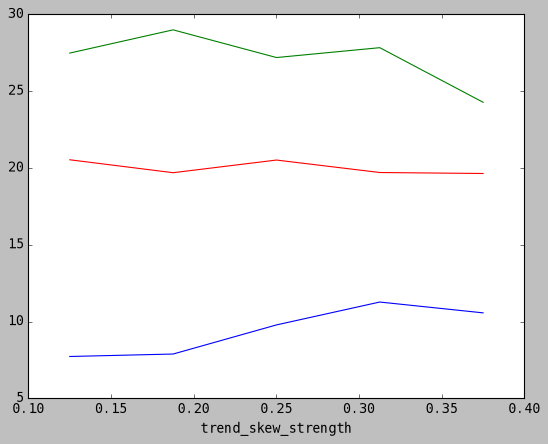

In [285]:
for v in df.half_spread_ticks_at_target.unique():
    df[df.half_spread_ticks_at_target == v].groupby('trend_skew_strength').total_pnl_usd.mean().plot()

<Axes: xlabel='half_life_seconds'>

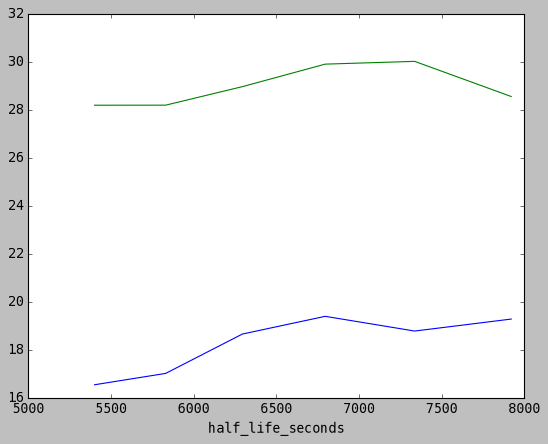

In [281]:
df.groupby('half_life_seconds').total_pnl_usd.mean().plot()
df.groupby('half_life_seconds').total_pnl_usd.max().plot()

<Axes: xlabel='trend_skew_strength'>

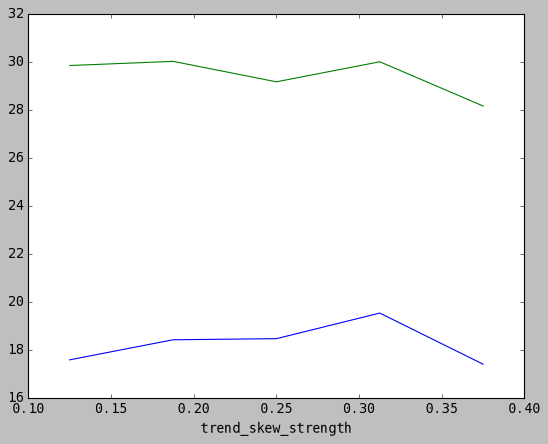

In [280]:
df.groupby('trend_skew_strength').total_pnl_usd.mean().plot()
df.groupby('trend_skew_strength').total_pnl_usd.max().plot()

In [205]:
np.linspace(0, 1, 5)

array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [201]:
np.geomspace(15, 180, 6)

array([ 15.        ,  24.65627744,  40.52880116,  66.61929105,
       109.50558154, 180.        ])

Text(0, 0.5, 'realised PnL of the closing order, $')

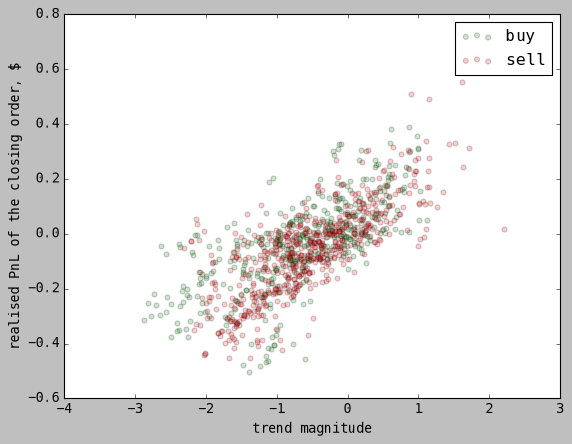

In [197]:
for side, c in [('buy', 'g'), ('sell', 'r')]:
    s = -1 if side == 'buy' else 1
    plt.scatter(
        s * df[df.side == side].trend_magnitude, df[df.side == side].realized_pnl_from_fill , c=c, alpha=0.2,
        label=side
    )
    # plt.title(side)
    # plt.show()

plt.legend()
plt.xlabel('trend magnitude')
plt.ylabel('realised PnL of the closing order, $')

Text(0, 0.5, 'realised PnL of the closing order, $')

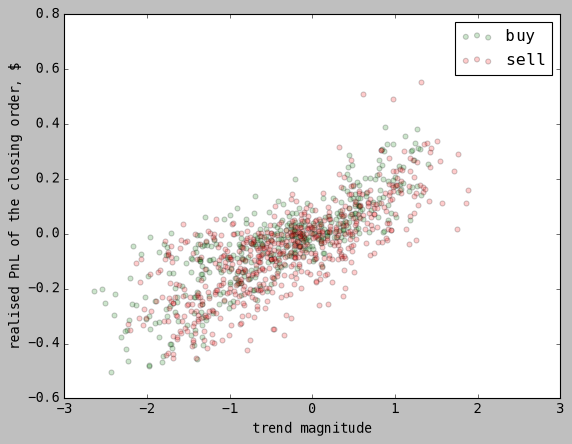

In [192]:
for side, c in [('buy', 'g'), ('sell', 'r')]:
    s = -1 if side == 'buy' else 1
    plt.scatter(
        s * df[df.side == side].trend_magnitude, df[df.side == side].realized_pnl_from_fill , c=c, alpha=0.2,
        label=side
    )
    # plt.title(side)
    # plt.show()

plt.legend()
plt.xlabel('trend magnitude')
plt.ylabel('realised PnL of the closing order, $')

In [ ]:
df.

In [78]:
df = pd.read_csv('../neutral_width_check_2026-03-19/summary.csv')

In [79]:
df = df.set_index('full_width_ticks')

In [80]:
df

,n_fills,traded_notional_usd,execution_pnl,fees,execution_minus_fees
full_width_ticks,,,,,
50,2030,195291.94752,-4.31249,39.058390,-43.370880
75,1328,128764.40544,-0.24791,25.752881,-26.000791
100,881,85353.07921,1.40718,17.070616,-15.663436
150,418,40549.92539,2.15083,8.109985,-5.959155
200,218,21449.11818,1.76745,4.289824,-2.522374
300,80,7918.38957,1.05056,1.583678,-0.533118
400,35,3463.57875,0.81410,0.692716,0.121384
500,19,1816.18949,0.39349,0.363238,0.030252
600,8,790.11024,0.27721,0.158022,0.119188


<Axes: xlabel='full_width_ticks'>

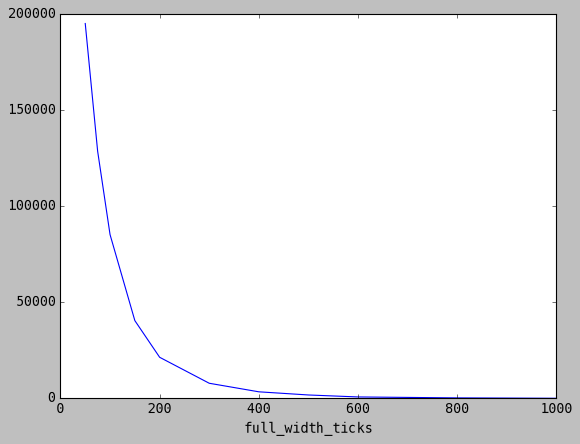

In [81]:
df.traded_notional_usd.plot()

In [65]:
df

,n_fills,traded_notional_usd,execution_pnl,fees,execution_minus_fees
full_width_ticks,,,,,
50,2030,195291.94752,-4.31249,39.058390,-43.370880
75,1328,128764.40544,-0.24791,25.752881,-26.000791
100,881,85353.07921,1.40718,17.070616,-15.663436
150,418,40549.92539,2.15083,8.109985,-5.959155


In [74]:
import numpy as np

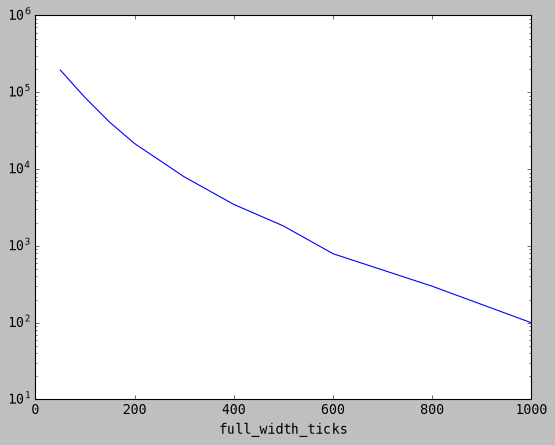

In [82]:
df.traded_notional_usd.plot()
plt.yscale('log')

Text(0, 0.5, 'turnover, $')

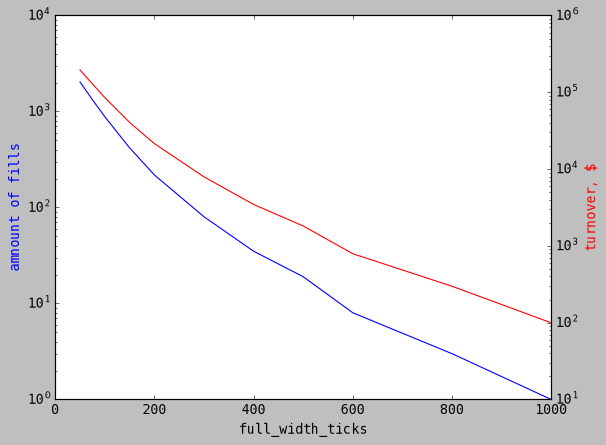

In [93]:
df.n_fills.plot()
plt.yscale('log')
plt.ylabel('amnount of fills', c='b')

ax = plt.twinx()
df.traded_notional_usd.plot(ax=ax, c='r')
plt.yscale('log')
plt.ylabel('turnover, $', c='r')

In [99]:
df

,n_fills,traded_notional_usd,execution_pnl,fees,execution_minus_fees
full_width_ticks,,,,,
50,2030,195291.94752,-4.31249,39.058390,-43.370880
75,1328,128764.40544,-0.24791,25.752881,-26.000791
100,881,85353.07921,1.40718,17.070616,-15.663436
150,418,40549.92539,2.15083,8.109985,-5.959155
200,218,21449.11818,1.76745,4.289824,-2.522374
300,80,7918.38957,1.05056,1.583678,-0.533118
400,35,3463.57875,0.81410,0.692716,0.121384
500,19,1816.18949,0.39349,0.363238,0.030252
600,8,790.11024,0.27721,0.158022,0.119188


Text(0, 0.5, 'execution PnL, $')

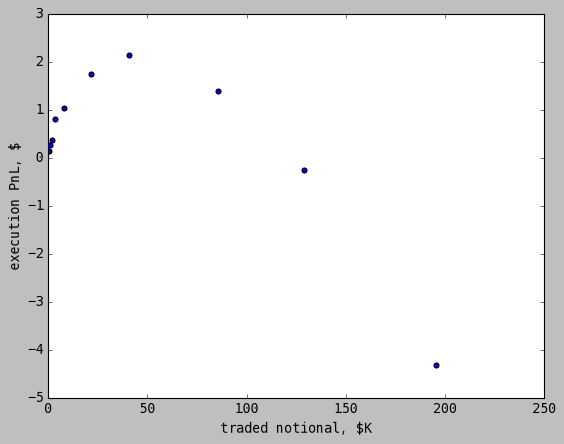

In [110]:
plt.scatter(df.traded_notional_usd / 1000, df.execution_pnl)
plt.xlabel('traded notional, $K')
plt.xlim(0, None)
# plt.xscale('log')
plt.ylabel('execution PnL, $')

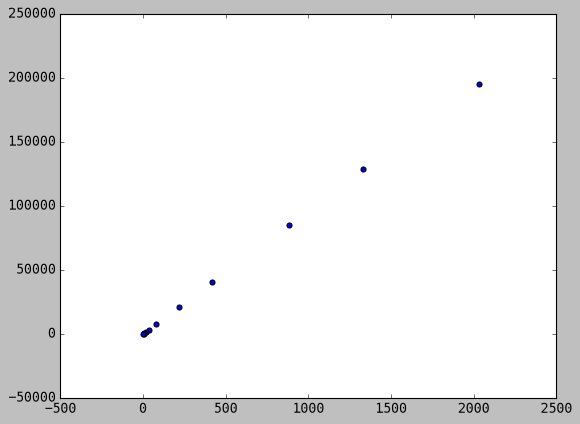

In [112]:
plt.scatter(df.n_fills, df.traded_notional_usd)

Text(0, 0.5, 'execution PnL, $')

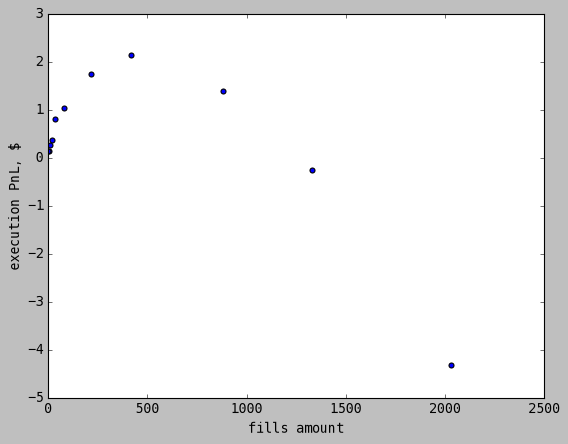

In [111]:
plt.scatter(df.n_fills, df.execution_pnl)
plt.xlabel('fills amount')
plt.xlim(0, None)
plt.ylabel('execution PnL, $')

<Axes: xlabel='full_width_ticks'>

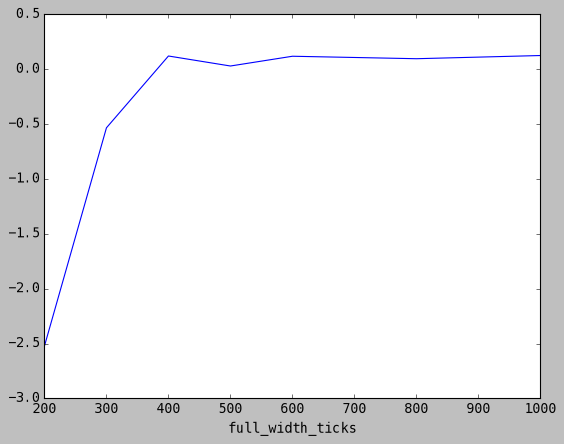

In [96]:
df.loc[200:].execution_minus_fees.plot()

Text(0, 0.5, 'execution PnL, bps of turnover')

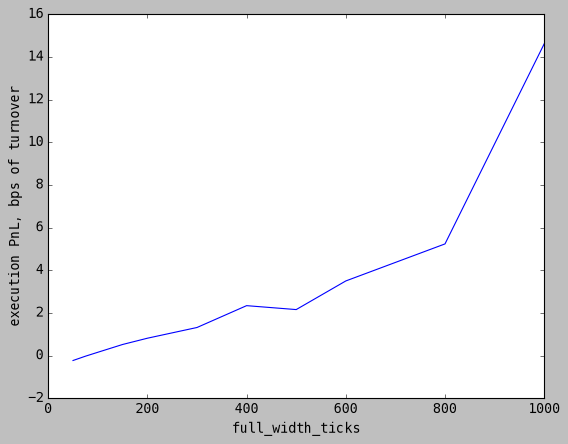

In [84]:
(1e4 * df.execution_pnl / df.traded_notional_usd).plot()
plt.ylabel('execution PnL, bps of turnover')

<Axes: xlabel='full_width_ticks'>

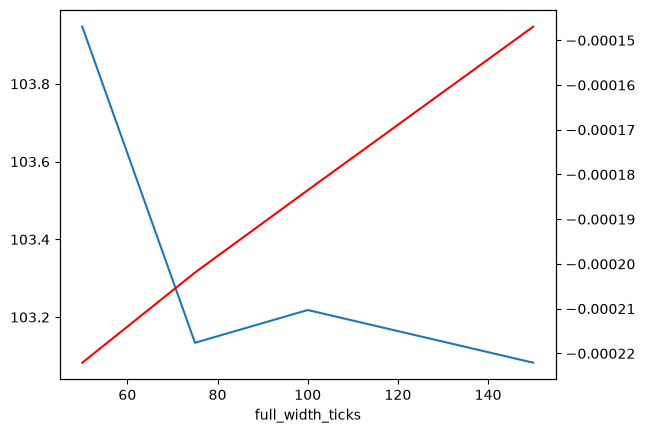

In [64]:
(df.n_fills / df.traded_notional_usd).plot()
df.execution_minus_fees/ df.traded_notional_usd).plot(ax=plt.twinx(), c='r')

In [7]:
import polars as pl

In [416]:
df = pl.read_parquet("../data/trades/2026-03-21.parquet").to_pandas()
df = df.set_index(pd.to_datetime(df.datetime)).drop('datetime', axis=1)

<Axes: xlabel='datetime'>

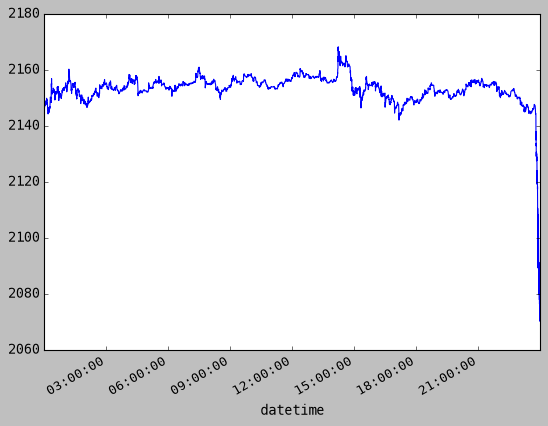

In [418]:
df.price.plot()

<Axes: xlabel='datetime'>

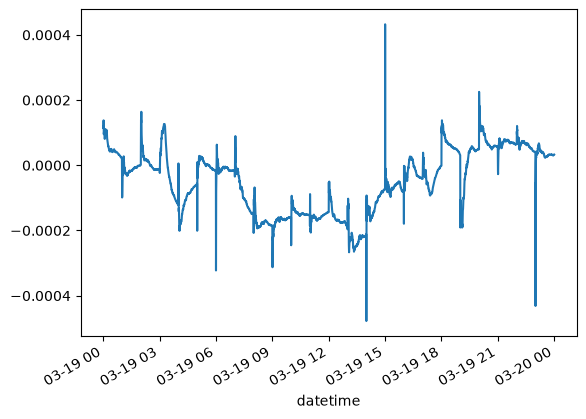

In [49]:
df.funding_rate.plot()

In [36]:
df = df.set_index(pd.to_datetime(df.datetime)).drop('datetime', axis=1)

<Axes: xlabel='datetime'>

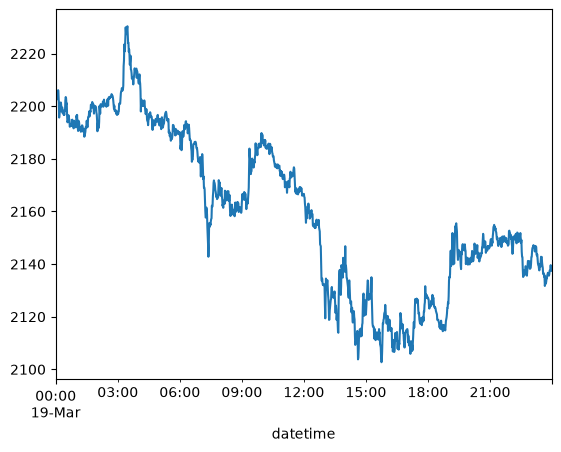

In [43]:
df.resample('1min').last().bid_price_1.plot()

Matplotlib is building the font cache; this may take a moment.


<Axes: >

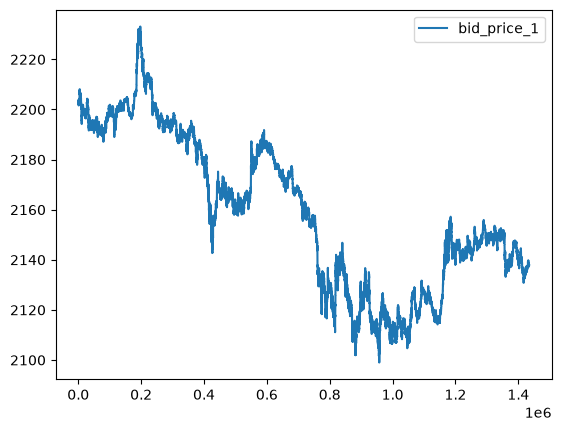

In [27]:
df.select('bid_price_1').to_pandas().plot()

In [16]:
df.schema

Schema([('datetime', Datetime(time_unit='ns', time_zone=None)),
        ('bid_price_1', Float64),
        ('bid_price_2', Float64),
        ('bid_price_3', Float64),
        ('bid_price_4', Float64),
        ('bid_price_5', Float64),
        ('bid_price_6', Float64),
        ('bid_price_7', Float64),
        ('bid_price_8', Float64),
        ('bid_price_9', Float64),
        ('bid_price_10', Float64),
        ('bid_price_11', Float64),
        ('bid_price_12', Float64),
        ('bid_price_13', Float64),
        ('bid_price_14', Float64),
        ('bid_price_15', Float64),
        ('bid_price_16', Float64),
        ('bid_price_17', Float64),
        ('bid_price_18', Float64),
        ('bid_price_19', Float64),
        ('bid_price_20', Float64),
        ('ask_price_1', Float64),
        ('ask_price_2', Float64),
        ('ask_price_3', Float64),
        ('ask_price_4', Float64),
        ('ask_price_5', Float64),
        ('ask_price_6', Float64),
        ('ask_price_7', Float64),
       

In [5]:
df = pd.read_parquet("../data/orderbook/2026-03-19.parquet")

ArrowKeyError: No type extension with name arrow.py_extension_type found